# Notebook 1 — Data, Validation & Targets

**Research question.** Can machine-learning models improve multi-horizon realised-volatility forecasts over established econometric models, and do the resulting forecasts identify mispriced volatility in SPY options?

**This notebook's job:** turn vendor downloads into a validated, documented, timestamp-safe panel and the forecast targets every later notebook uses. Nothing here is fitted, so nothing here can overfit.

| | |
|---|---|
| **Inputs** | Yahoo Finance (SPY OHLCV, dividends, splits) · VIX, VIX9D, VIX3M (CBOE → FRED → Yahoo fallbacks) · 3-month T-bill (FRED DGS3MO → Yahoo ^IRX) |
| **Outputs** | `data/processed/panel.parquet` · `targets.parquet` · `data_dictionary.csv` · `validation_report.csv` · EDA figures |
| **Next** | Notebook 2 reads `panel.parquet` to build features |

**Rules enforced in this notebook**
1. Row *t* contains only information observable at the close of session *t*.
2. Targets cover returns *t+1 … t+h* and are stored in **variance** space.
3. Exploratory analysis uses the **development period (2015–2022) only**. The 2023–2025 test window stays unseen until models are frozen in Notebook 3.
4. Every raw file is hashed; every processed file is hashed. A rerun on cached data reproduces results bit-for-bit.

## 0. Setup

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

from src.config import load_config
from src.data import acquire, validate, synthetic
from src.data.align import build_panel
from src.targets import build_targets, brute_force_rv

cfg, P = load_config(ROOT)
SEED = cfg["project"]["seed"]
np.random.seed(SEED)
H = cfg["targets"]["horizons"]
ANN = cfg["targets"]["annualization"]

# "live" downloads real data; "synthetic" runs fully offline on simulated data.
DATA_MODE = os.environ.get("VOLRES_DATA_MODE", "live")
FORCE_DOWNLOAD = False          # True re-downloads and overwrites the raw cache

# Synthetic runs write to separate folders so they can never contaminate real results.
sub = "_synthetic" if DATA_MODE == "synthetic" else ""
RAW = P.raw / sub if sub else P.raw
OUT = P.processed / sub if sub else P.processed
FIG = P.figures / sub if sub else P.figures
for p in (RAW, OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def savefig(fig, name):
    fig.savefig(FIG / f"nb01_{name}.png", bbox_inches="tight", dpi=150)

if DATA_MODE == "synthetic":
    print("=" * 72 + "\nSYNTHETIC MODE: pipeline test only. These numbers are NOT research results.\n" + "=" * 72)

env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "matplotlib": matplotlib.__version__, "data_mode": DATA_MODE}
print(json.dumps(env, indent=1))

{
 "python": "3.11.17",
 "numpy": "2.4.6",
 "pandas": "3.0.6",
 "matplotlib": "3.11.2",
 "data_mode": "live"
}


## 1. Acquisition

Raw files are cached in `data/raw/` with a manifest (source, query, UTC download time, row count, SHA256). Later runs load the cache, so a vendor silently revising history cannot change your results. To refresh, set `FORCE_DOWNLOAD = True`, rerun, and note the new manifest in your report.

The download window (from mid-2014 to Feb 2026) is wider than the research sample (2015–2025) on purpose:
- **Front buffer:** 60-day features must be fully warmed up on the first sample day.
- **Back buffer:** a 20-day target on 31 Dec 2025 needs returns through late January 2026.

Each implied-vol and rate series has **ordered fallback sources** in `config.yaml`, with retries and backoff. The source actually used is written to the manifest and the data dictionary. VIX3M and VIX9D are optional: if every source fails, the pipeline continues and records the gap.

If a required series fails everywhere (e.g. a firewall), download it by hand and save it as `data/raw/manual/<name>.csv` with a date column first and the value column last. It then overrides the network sources and is logged as `manual:` in the manifest.

In [2]:
if DATA_MODE == "synthetic":
    d = cfg["data"]
    raw = synthetic.generate(d["download_start"], d["download_end"], seed=SEED)
    acquire.save_synthetic(raw, RAW)
else:
    raw = acquire.acquire_all(cfg, RAW, force=FORCE_DOWNLOAD)

manifest = acquire.verify_manifest(RAW)
assert manifest["hash_ok"].all(), "A cached raw file no longer matches its recorded hash."
manifest

cached     spy      2945 rows  (yahoo:SPY)
cached     vix      2973 rows  (cboe:https://cdn.cboe.com/api/global/us_indices/daily_prices/VIX_History.csv)
cached     vix9d    2945 rows  (cboe:https://cdn.cboe.com/api/global/us_indices/daily_prices/VIX9D_History.csv)
cached     vix3m    2945 rows  (cboe:https://cdn.cboe.com/api/global/us_indices/daily_prices/VIX3M_History.csv)
cached     rate_3m  3055 rows  (manual:rate_3m.csv)


,file,rows,first,last,downloaded_utc,hash_ok
0,spy,2945,2014-06-02,2026-02-13,2026-10-12T06:47:44+00:00,True
1,vix,2973,2014-06-02,2026-02-13,2026-10-12T06:47:46+00:00,True
2,vix9d,2945,2014-06-02,2026-02-13,2026-10-12T06:47:47+00:00,True
3,vix3m,2945,2014-06-02,2026-02-13,2026-10-12T06:47:48+00:00,True
4,rate_3m,3055,2014-06-02,2026-02-13,2026-10-12T06:47:48+00:00,True


## 2. Validation suite

Each check is a function in `src/data/validate.py` with a severity:

- **FAIL**: the pipeline stops. Examples are duplicate dates, non-positive prices, and High below Close.
- **WARN**: a plausible data issue. Inspect it and record it in the report's limitations section.
- **INFO**: an expected market feature. Crash-day returns are kept, never winsorised, because they are exactly what a volatility model must handle.

Vendors occasionally publish a High a few cents below the Close. Breaches under 0.2% of price are clamped, and **every repair is logged and saved**. Larger breaches still fail.

In [3]:
report_before = validate.run_all(raw, cfg)
raw["spy"], repair_log = validate.repair_ohlc(raw["spy"])
report = validate.run_all(raw, cfg) if len(repair_log) else report_before

print(f"OHLC repairs applied: {len(repair_log)}")
if len(repair_log):
    display(repair_log)

def _style(row):
    if not row["passed"] and row["severity"] == "FAIL":
        return ["background-color:#f8d7da"] * len(row)
    if not row["passed"]:
        return ["background-color:#fff3cd"] * len(row)
    return [""] * len(row)

display(report[["name", "severity", "passed", "n_issues", "detail", "examples"]].style.apply(_style, axis=1))
report.to_csv(OUT / "validation_report.csv", index=False)
repair_log.to_csv(OUT / "ohlc_repairs.csv")
validate.assert_no_failures(report)
print("No FAIL-severity issues. Proceeding.")

OHLC repairs applied: 0


,name,severity,passed,n_issues,detail,examples
0,SPY: unique dates,FAIL,True,0,duplicate index entries,[]
1,SPY: sorted dates,FAIL,True,0,,[]
2,SPY: no missing prices,FAIL,True,0,NaN in OHLC/AdjClose,[]
3,SPY: positive prices,FAIL,True,0,non-positive price,[]
4,"SPY: High >= max(Open, Close)",FAIL,True,0,,[]
5,"SPY: Low <= min(Open, Close)",FAIL,True,0,,[]
6,SPY: non-degenerate range (H > L),WARN,True,0,H == L breaks log-range estimators,[]
7,SPY: positive volume,WARN,True,0,zero/negative volume days,[]
8,SPY: no stale closes,WARN,True,0,runs of >= 2 identical closes,[]
9,SPY: no missing NYSE sessions,WARN,True,0,,[]


No FAIL-severity issues. Proceeding.


**How to read the warnings**

- *Missing values on SPY sessions (VIX, rate):* FRED skips some days the stock market trades, such as bond-market holidays for DGS3MO. These are forward-filled within the configured limit (1 day for VIX, 5 for rates) and flagged in `*_ffilled` columns. Forward-fill uses only past values. A unit test proves it.
- *Adjustment-factor changes off dividend dates:* if this fires on real data, Yahoo has revised its adjustment. Inspect the listed dates before continuing.
- *Extreme returns:* expect March 2020 here. These are signal, not noise.

## 3. Aligned panel

The SPY session calendar is the master index. OHLC prices are **dividend-adjusted** with the `AdjClose/Close` factor. Range estimators such as log(H/L) are unaffected by the factor, but the overnight return log(O<sub>t</sub>/C<sub>t−1</sub>) would otherwise show a fake gap on every ex-dividend date.

Returns are decomposed as close-to-close = overnight + intraday, and the identity is asserted to 1e-10.

In [4]:
panel = build_panel(raw, cfg)

coverage = pd.DataFrame({
    "first_valid": {c: panel[c].first_valid_index() for c in ["close", "vix", "vix9d", "vix3m", "rate"] if c in panel},
    "missing_in_sample": {c: int(panel.loc[panel.in_sample, c].isna().sum()) for c in ["close", "vix", "vix9d", "vix3m", "rate"] if c in panel},
    "ffilled_in_sample": {c: int(panel.loc[panel.in_sample, f"{c}_ffilled"].sum()) for c in ["vix", "vix9d", "vix3m", "rate"] if f"{c}_ffilled" in panel},
})
display(coverage)
print(f"Panel: {len(panel):,} sessions ({panel.index.min().date()} -> {panel.index.max().date()}), "
      f"research sample: {int(panel.in_sample.sum()):,} sessions")
panel.loc[panel.in_sample].head()

,first_valid,missing_in_sample,ffilled_in_sample
close,2014-06-02,0,NaN
vix,2014-06-02,0,0
vix9d,2014-06-02,0,0
vix3m,2014-06-02,0,0
rate,2014-06-02,0,20


Panel: 2,945 sessions (2014-06-02 -> 2026-02-13), research sample: 2,766 sessions


,open,high,low,close,close_raw,adj_factor,volume,dividend,ret,ret_on,ret_id,vix,vix_ffilled,vix_var,vix9d,vix9d_ffilled,vix9d_var,vix3m,vix3m_ffilled,vix3m_var,rate,rate_ffilled,rate_daily,in_sample
date,,,,,,,,,,,,,,,,,,,,,,,,
2015-01-02,170.05,170.462,168.238,169.267,205.43,0.823967,1.21466e+08,0,-0.000535684,0.00407816,-0.00461385,17.79,False,0.0316484,16.47,False,0.0271261,19.46,False,0.0378692,0.0002,False,7.93571e-07,True
2015-01-05,168.229,168.394,165.906,166.211,201.72,0.823967,1.69633e+08,0,-0.0182245,-0.00615209,-0.0120724,19.92,False,0.0396806,19.45,False,0.0378303,20.79,False,0.0432224,0.0003,False,1.1903e-06,True
2015-01-06,166.515,167.035,163.854,164.645,199.82,0.823967,2.09151e+08,0,-0.00946363,0.0018325,-0.0112961,21.12,False,0.0446054,20.53,False,0.0421481,21.42,False,0.0458816,0.0003,False,1.1903e-06,True
2015-01-07,165.963,167.035,165.518,166.697,202.31,0.823967,1.25347e+08,0,0.0123841,0.00797525,0.00440889,19.31,False,0.0372876,17.59,False,0.0309408,20.08,False,0.0403206,0.0003,False,1.1903e-06,True
2015-01-08,168.097,169.869,168.081,169.655,205.9,0.823967,1.47218e+08,0,0.0175892,0.00836755,0.0092216,17.01,False,0.028934,15.04,False,0.0226202,18.66,False,0.0348196,0.0003,False,1.1903e-06,True


## 4. Targets

For a forecast issued at the close of day *t*:

$$RV_{t,h} \;=\; \frac{252}{h}\sum_{i=1}^{h} r_{t+i}^{2}\qquad h\in\{5,20\}$$

This is stored as annualised **variance** (`rv_var_h`). Volatility (`rv_vol_h`) and log-variance (`rv_logvar_h`) are derived columns.

- **Variance**, because QLIKE, the variance risk premium IV² − RV, and GARCH forecasts are all defined on variance. Mixing volatility and variance across models is a common error that silently invalidates comparisons.
- **Log-variance**, because it is the training target for the ML models. It is near-Gaussian, while variance is heavily right-skewed (shown in §5.5).
- **`label_end_h`**, the date of the last return inside each target window. Overlapping windows mean adjacent rows share up to *h−1* returns. Notebook 3 uses `label_end_h` to purge training rows whose labels leak into the validation period.

Two independent correctness checks run below: a brute-force loop comparison, and a perturbation test showing that the target ignores *r<sub>t</sub>* itself.

In [5]:
targets = build_targets(panel, H, ANN)

# Check 1: vectorised implementation equals a slow reference loop
for h in H:
    ref = brute_force_rv(panel["ret"], h, ANN)
    diff = (targets[f"rv_var_{h}"] - ref).abs().max()
    assert diff < 1e-14, f"h={h}: mismatch {diff}"

# Check 2: perturb r_t and confirm the target at t is unchanged but t-1 changes
t = panel.index.get_loc(panel.index[panel.in_sample][500])
r_shock = panel["ret"].copy(); r_shock.iloc[t] += 0.05
for h in H:
    alt = build_targets(panel.assign(ret=r_shock), [h], ANN)[f"rv_var_{h}"]
    assert alt.iloc[t] == targets[f"rv_var_{h}"].iloc[t], "target at t must not use r_t"
    assert alt.iloc[t - 1] != targets[f"rv_var_{h}"].iloc[t - 1], "target at t-1 must use r_t"

# Check 3: every in-sample row has a defined target (back buffer is long enough)
for h in H:
    n_nan = targets.loc[panel.in_sample, f"rv_var_{h}"].isna().sum()
    assert n_nan == 0, f"h={h}: {n_nan} in-sample targets undefined; extend download_end"

print("All target checks passed.")
targets.loc[panel.in_sample].describe().T

All target checks passed.


,count,mean,min,25%,50%,75%,max,std
rv_var_5,"2,766",0.0317999,0.000241135,0.00554845,0.0132652,0.0295789,1.80117,0.0935075
rv_vol_5,"2,766",0.140037,0.0155285,0.0744879,0.115175,0.171985,1.34208,0.110426
rv_logvar_5,"2,766",-4.34287,-8.33016,-5.19424,-4.32261,-3.52069,0.588434,1.25511
label_end_5,2766,2020-07-07 19:08:27.592190720,2015-01-09 00:00:00,2017-10-06 18:00:00,2020-07-08 12:00:00,2023-04-05 18:00:00,2026-01-08 00:00:00,NaN
rv_var_20,"2,766",0.0317619,0.00107384,0.00833248,0.0152253,0.0323829,0.852303,0.0726594
rv_vol_20,"2,766",0.148474,0.0327695,0.0912824,0.123391,0.179952,0.923203,0.098594
rv_logvar_20,"2,766",-4.09397,-6.83652,-4.78759,-4.1848,-3.43013,-0.159813,0.998333
label_end_20,2766,2020-07-29 14:05:27.982646528,2015-02-02 00:00:00,2017-10-27 18:00:00,2020-07-29 12:00:00,2023-04-27 18:00:00,2026-01-30 00:00:00,NaN


### 4.1 Split map and purge preview

The splits are fixed in `config.yaml` before any model exists. Tuning uses expanding-window folds that validate on 2019, 2020, 2021 and 2022. **2023–2025 is the sealed test set.**

The table counts how many training rows each fold must purge, because their target windows end inside the validation year. With *h* = 20, each boundary loses about 20 rows.

In [6]:
sp = cfg["splits"]
idx = panel.index[panel.in_sample]
rows = []
for y in sp["val_years"]:
    tr = idx[idx < f"{y}-01-01"]
    va = idx[(idx >= f"{y}-01-01") & (idx <= f"{y}-12-31")]
    rec = {"fold": f"val {y}", "train": f"{tr.min().date()} .. {tr.max().date()}", "n_train": len(tr), "n_val": len(va)}
    for h in H:
        ends = targets.loc[tr, f"label_end_{h}"]
        rec[f"purged_h{h}"] = int((ends >= va.min()).sum())
    rows.append(rec)
te = idx[idx >= sp["test_start"]]
rows.append({"fold": "TEST (sealed)", "train": f"{idx.min().date()} .. 2022-12-31",
             "n_train": int((idx < sp["test_start"]).sum()), "n_val": len(te),
             **{f"purged_h{h}": int((targets.loc[idx[idx < sp['test_start']], f'label_end_{h}'] >= te.min()).sum()) for h in H}})
split_map = pd.DataFrame(rows).set_index("fold")
split_map

,train,n_train,n_val,purged_h5,purged_h20
fold,,,,,
val 2019,2015-01-02 .. 2018-12-31,1006,252,5,20
val 2020,2015-01-02 .. 2019-12-31,1258,253,5,20
val 2021,2015-01-02 .. 2020-12-31,1511,252,5,20
val 2022,2015-01-02 .. 2021-12-31,1763,251,5,20
TEST (sealed),2015-01-02 .. 2022-12-31,2014,752,5,20


## 5. Exploratory analysis (development period only)

Each subsection below tests a stylised fact that justifies a specific modelling choice later. All statistics use **2015–2022 only**.

| Fact | If present, it justifies |
|---|---|
| Fat tails | Student-t GARCH innovations; QLIKE rather than MSE alone |
| Volatility clustering | GARCH-family and HAR benchmarks; lagged-volatility features |
| Leverage effect | EGARCH and GJR-GARCH; signed-return features |
| Large overnight share of variance | Yang-Zhang estimator over Parkinson/Garman-Klass |
| Skewed variance, symmetric log-variance | log-variance as the ML training target |

In [7]:
DEV = panel.in_sample & (panel.index < cfg["splits"]["test_start"])
dev = panel.loc[DEV]
tdev = targets.loc[DEV]
r = dev["ret"].dropna()
print(f"Development period: {dev.index.min().date()} -> {dev.index.max().date()}  ({len(dev):,} sessions)")

Development period: 2015-01-02 -> 2022-12-30  (2,014 sessions)


### 5.1 Return distribution

,daily log return
ann. mean,0.0960008
ann. vol,0.186909
skewness,-0.808382
excess kurtosis,13.3981
Jarque-Bera stat,"15,283.1"
JB p-value,0
min daily,-0.115887
max daily,0.0867311


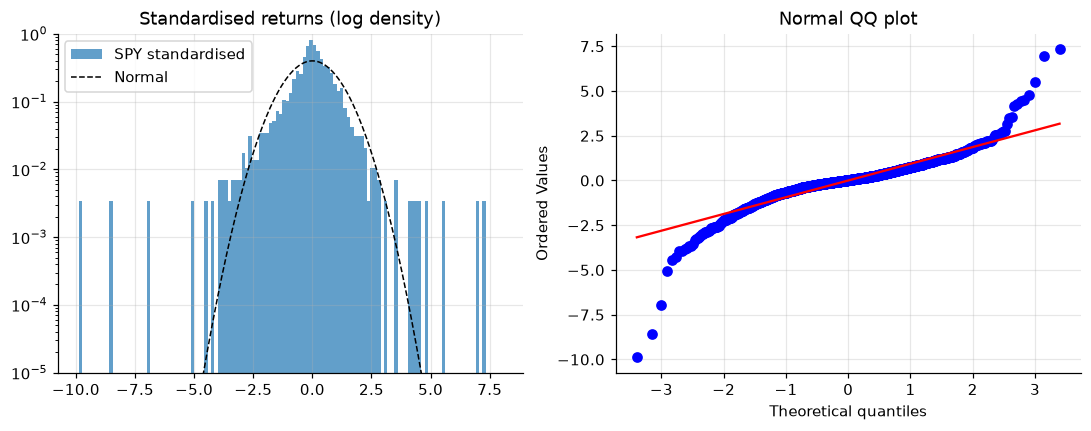

In [8]:
jb = stats.jarque_bera(r)
summary = pd.Series({
    "ann. mean": r.mean() * ANN,
    "ann. vol": r.std() * np.sqrt(ANN),
    "skewness": stats.skew(r),
    "excess kurtosis": stats.kurtosis(r),
    "Jarque-Bera stat": jb.statistic,
    "JB p-value": jb.pvalue,
    "min daily": r.min(), "max daily": r.max(),
}, name="daily log return")
display(summary.to_frame())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
zr = (r - r.mean()) / r.std()
ax[0].hist(zr, bins=120, density=True, alpha=0.7, label="SPY standardised")
xs = np.linspace(-8, 8, 400)
ax[0].plot(xs, stats.norm.pdf(xs), "k--", lw=1, label="Normal")
ax[0].set_yscale("log"); ax[0].set_ylim(1e-5, 1); ax[0].set_title("Standardised returns (log density)"); ax[0].legend()
stats.probplot(zr, dist="norm", plot=ax[1]); ax[1].set_title("Normal QQ plot")
savefig(fig, "return_distribution"); plt.show()

### 5.2 Volatility clustering

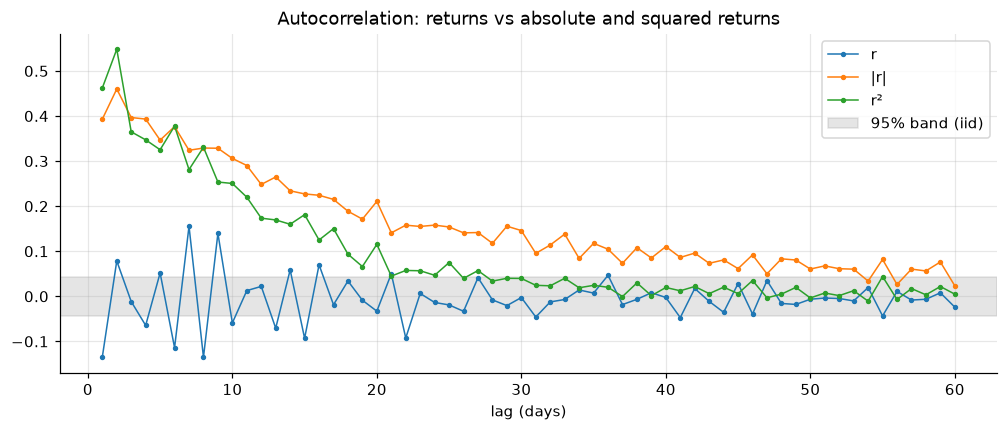

lb_stat   lb_pvalue
r  10  221.767 4.56059e-42
   20   273.13 2.38957e-46
r² 10 2,691.11           0
   20 3,158.42           0

In [9]:
LAGS = 60
acfs = pd.DataFrame({
    "r": acf(r, nlags=LAGS, fft=True)[1:],
    "|r|": acf(r.abs(), nlags=LAGS, fft=True)[1:],
    "r²": acf(r ** 2, nlags=LAGS, fft=True)[1:],
}, index=range(1, LAGS + 1))
band = 1.96 / np.sqrt(len(r))

fig, ax = plt.subplots()
for c in acfs:
    ax.plot(acfs.index, acfs[c], marker="o", ms=2.5, lw=1, label=c)
ax.axhspan(-band, band, color="grey", alpha=0.2, label="95% band (iid)")
ax.set_xlabel("lag (days)"); ax.set_title("Autocorrelation: returns vs absolute and squared returns"); ax.legend()
savefig(fig, "acf_clustering"); plt.show()

lb = pd.concat({name: acorr_ljungbox(s, lags=[10, 20], return_df=True)
                for name, s in {"r": r, "r²": r ** 2}.items()})
lb

### 5.3 Leverage effect

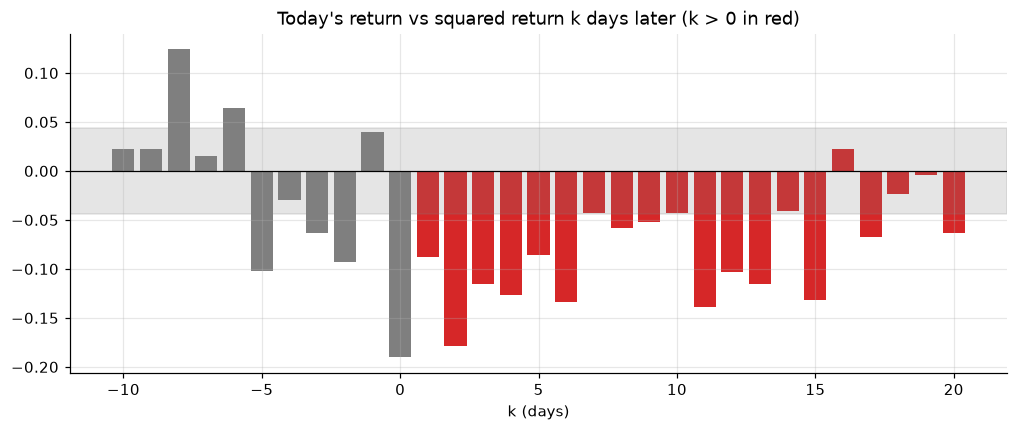

corr(r_t, future RV_h): {5: -0.158, 20: -0.133} 
Negative values mean down days predict higher future variance, the asymmetry EGARCH and GJR model.


In [10]:
r2 = r ** 2
xcorr = pd.Series({k: r.corr(r2.shift(-k)) for k in range(-10, 21)}, name="corr(r_t, r²_{t+k})")

fig, ax = plt.subplots()
ax.bar(xcorr.index, xcorr.values, color=["tab:grey" if k <= 0 else "tab:red" for k in xcorr.index])
ax.axhline(0, color="k", lw=0.8)
ax.axhspan(-band, band, color="grey", alpha=0.2)
ax.set_xlabel("k (days)"); ax.set_title("Today's return vs squared return k days later (k > 0 in red)")
savefig(fig, "leverage_effect"); plt.show()

lev = {h: r.corr(tdev[f"rv_var_{h}"].reindex(r.index)) for h in H}
print("corr(r_t, future RV_h):", {h: round(float(v), 3) for h, v in lev.items()},
      "\nNegative values mean down days predict higher future variance, the asymmetry EGARCH and GJR model.")

### 5.4 Overnight share of variance

,share of close-to-close variance
overnight,0.432716
intraday,0.524492
2·cov,0.0427916


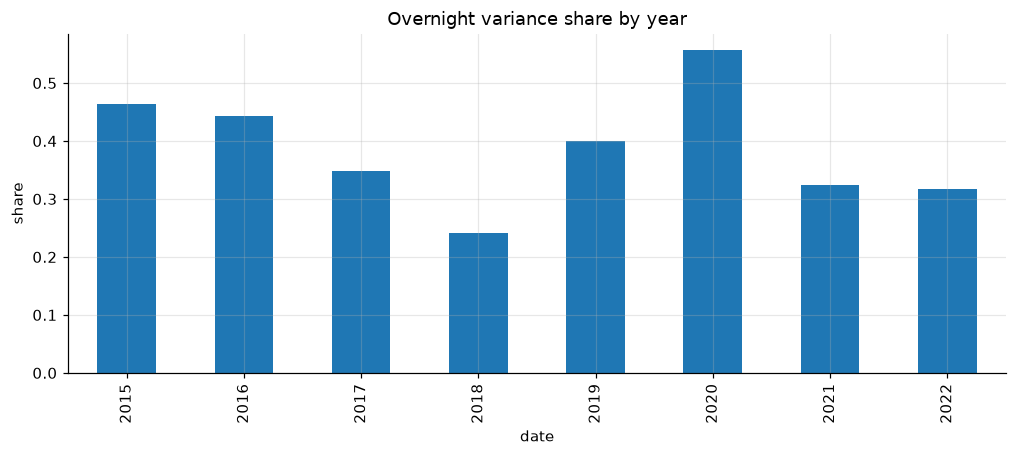

Parkinson and Garman-Klass use only the trading-day range, so they miss this overnight component. Notebook 2 adds Yang-Zhang, which combines overnight, open-to-close and range terms.


In [11]:
share = pd.Series({
    "overnight": dev["ret_on"].var(),
    "intraday": dev["ret_id"].var(),
    "2·cov": 2 * dev["ret_on"].cov(dev["ret_id"]),
}) / dev["ret"].var()
display(share.to_frame("share of close-to-close variance"))

by_year = dev.groupby(dev.index.year).apply(lambda g: g["ret_on"].var() / g["ret"].var())
by_year.plot.bar(title="Overnight variance share by year", ylabel="share"); plt.show()
print("Parkinson and Garman-Klass use only the trading-day range, so they miss this overnight "
      "component. Notebook 2 adds Yang-Zhang, which combines overnight, open-to-close and range terms.")

### 5.5 Why log-variance is the ML target

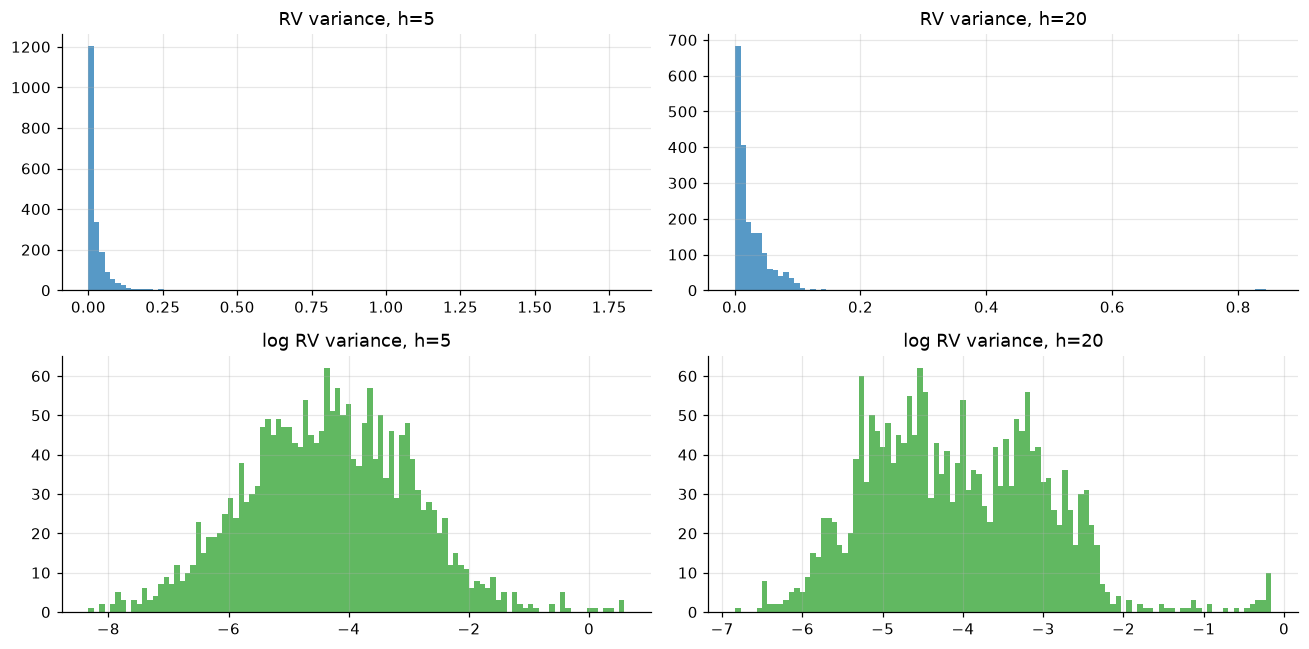

,skew(var),skew(log var),kurt(var),kurt(log var)
h,,,,
5,11.617,0.0790653,168.098,0.0817085
20,7.76545,0.440279,67.1877,0.317379


In [12]:
fig, ax = plt.subplots(2, len(H), figsize=(12, 6))
rows = []
for j, h in enumerate(H):
    v, lv = tdev[f"rv_var_{h}"].dropna(), tdev[f"rv_logvar_{h}"].dropna()
    ax[0, j].hist(v, bins=100, alpha=0.75); ax[0, j].set_title(f"RV variance, h={h}")
    ax[1, j].hist(lv, bins=100, alpha=0.75, color="tab:green"); ax[1, j].set_title(f"log RV variance, h={h}")
    rows.append({"h": h, "skew(var)": stats.skew(v), "skew(log var)": stats.skew(lv),
                 "kurt(var)": stats.kurtosis(v), "kurt(log var)": stats.kurtosis(lv)})
fig.tight_layout(); savefig(fig, "target_distributions"); plt.show()
pd.DataFrame(rows).set_index("h")

### 5.6 Implied vs subsequent realised variance (descriptive preview)

The ex-post variance risk premium is VIX²<sub>t</sub> − RV<sub>t,20</sub>. VIX is a 30-calendar-day measure, about 21 trading days, so *h* = 20 is the matched horizon.

This is **measured after the fact**, not a tradable signal. It only motivates the question for Notebook 5. Remember also that VIX is computed from SPX options, not SPY options.

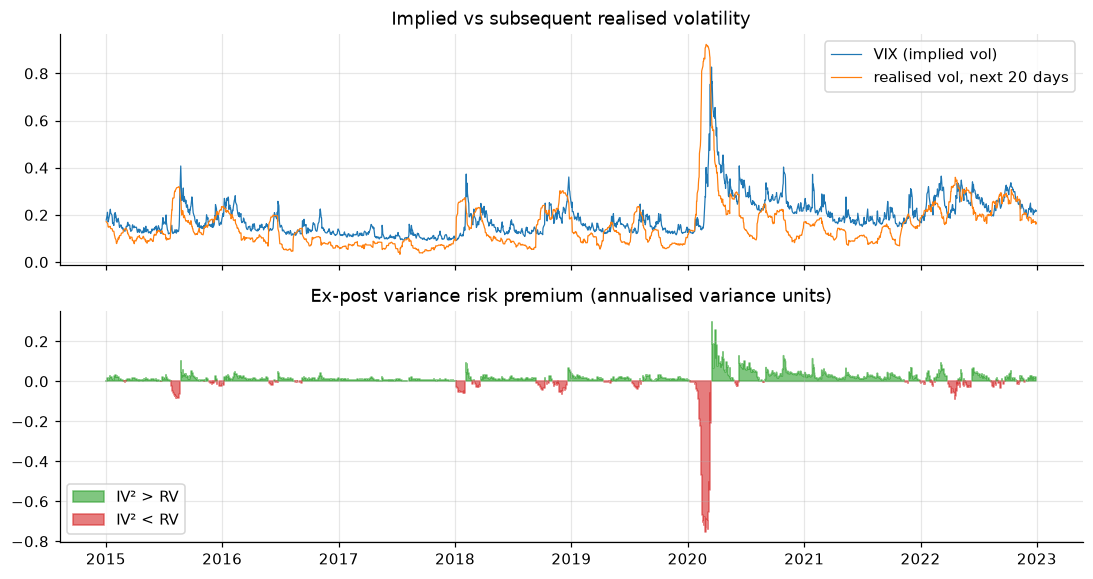

mean ex-post VRP: 0.00652 | median: 0.01106 | share positive: 81.2%


In [13]:
vrp = (dev["vix_var"] - tdev["rv_var_20"]).dropna()
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(dev.index, np.sqrt(dev["vix_var"]), lw=0.8, label="VIX (implied vol)")
ax[0].plot(tdev.index, tdev["rv_vol_20"], lw=0.8, label="realised vol, next 20 days")
ax[0].legend(); ax[0].set_title("Implied vs subsequent realised volatility")
ax[1].fill_between(vrp.index, 0, vrp, where=vrp >= 0, color="tab:green", alpha=0.6, step="mid", label="IV² > RV")
ax[1].fill_between(vrp.index, 0, vrp, where=vrp < 0, color="tab:red", alpha=0.6, step="mid", label="IV² < RV")
ax[1].set_title("Ex-post variance risk premium (annualised variance units)"); ax[1].legend()
savefig(fig, "vrp_preview"); plt.show()

print(f"mean ex-post VRP: {vrp.mean():.5f} | median: {vrp.median():.5f} | share positive: {(vrp > 0).mean():.1%}")

### 5.7 Timeline with stress windows and split boundaries

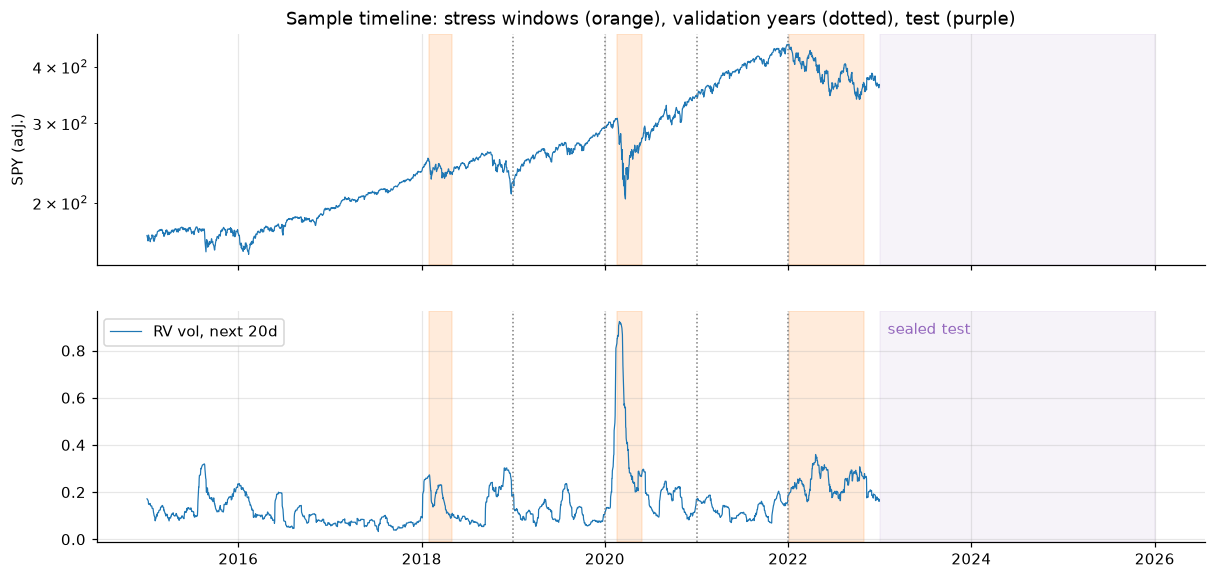

In [14]:
STRESS = {"Feb 2018 Volmageddon": ("2018-01-29", "2018-04-30"),
          "COVID crash": ("2020-02-20", "2020-05-29"),
          "2022 rate hikes": ("2022-01-03", "2022-10-31")}
ins = panel.loc[panel.in_sample]
# test-period values are masked: the test window is shown, its outcomes are not
dev_only = lambda s: s.where(s.index < cfg["splits"]["test_start"])
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(ins.index, dev_only(ins["close"]), lw=0.8); ax[0].set_ylabel("SPY (adj.)"); ax[0].set_yscale("log")
ax[1].plot(ins.index, dev_only(targets.loc[ins.index, "rv_vol_20"]), lw=0.8, label="RV vol, next 20d")
for a in ax:
    for name, (s, e) in STRESS.items():
        a.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="tab:orange", alpha=0.15)
    for y in cfg["splits"]["val_years"]:
        a.axvline(pd.Timestamp(f"{y}-01-01"), color="grey", ls=":", lw=1)
    a.axvspan(pd.Timestamp(cfg["splits"]["test_start"]), ins.index.max(), color="tab:purple", alpha=0.08)
ax[1].text(pd.Timestamp("2023-02-01"), ax[1].get_ylim()[1] * 0.9, "sealed test", color="tab:purple")
ax[1].legend(loc="upper left"); ax[0].set_title("Sample timeline: stress windows (orange), validation years (dotted), test (purple)")
savefig(fig, "timeline"); plt.show()

Test-period values are masked in the plot: the window is shown, its outcomes are not. No statistic in this notebook is computed on test data.

## 6. Data dictionary

In [15]:
SRC = {k: v["source"] for k, v in acquire.load_manifest(RAW).items()}   # the source actually used
DESC = {
    "open": ("Dividend-adjusted open", "USD", "yahoo", "close t"),
    "high": ("Dividend-adjusted high", "USD", "yahoo", "close t"),
    "low": ("Dividend-adjusted low", "USD", "yahoo", "close t"),
    "close": ("Dividend-adjusted close (= Yahoo AdjClose)", "USD", "yahoo", "close t"),
    "close_raw": ("Split-adjusted, unadjusted-for-dividends close", "USD", "yahoo", "close t"),
    "adj_factor": ("AdjClose / Close", "ratio", "derived", "close t"),
    "volume": ("Shares traded", "shares", "yahoo", "close t"),
    "dividend": ("Cash dividend on ex-date", "USD/share", "yahoo", "close t"),
    "ret": ("log(close_t / close_{t-1})", "log return", "derived", "close t"),
    "ret_on": ("Overnight log(open_t / close_{t-1})", "log return", "derived", "open t"),
    "ret_id": ("Intraday log(close_t / open_t)", "log return", "derived", "close t"),
    "vix": ("CBOE VIX close, 30-calendar-day SPX implied vol", "vol points", SRC.get("vix", "n/a"), "16:15 ET t"),
    "vix_var": ("(vix/100)^2", "ann. variance", "derived", "16:15 ET t"),
    "vix9d": ("CBOE VIX9D close, 9-day SPX implied vol", "vol points", SRC.get("vix9d", "n/a"), "16:15 ET t"),
    "vix9d_var": ("(vix9d/100)^2", "ann. variance", "derived", "16:15 ET t"),
    "vix3m": ("CBOE 3-month VIX close", "vol points", SRC.get("vix3m", "n/a"), "16:15 ET t"),
    "vix3m_var": ("(vix3m/100)^2", "ann. variance", "derived", "16:15 ET t"),
    "rate": ("3-month T-bill yield (DGS3MO CMT; ^IRX if FRED unavailable)", "decimal p.a.", SRC.get("rate_3m", "n/a"), "EOD t"),
    "rate_daily": ("log(1 + rate) / 252", "per session", "derived", "EOD t"),
    "in_sample": ("2015-01-01 <= date <= 2025-12-31", "bool", "config", "-"),
}
for k in ("vix", "vix9d", "vix3m", "rate"):
    DESC[f"{k}_ffilled"] = (f"{k} carried forward from a prior session", "bool", "derived", "-")
for h in H:
    DESC[f"rv_var_{h}"] = (f"(252/{h}) * sum r^2 over t+1..t+{h}", "ann. variance", "target", f"close t+{h}")
    DESC[f"rv_vol_{h}"] = (f"sqrt(rv_var_{h})", "ann. vol", "target", f"close t+{h}")
    DESC[f"rv_logvar_{h}"] = (f"log(rv_var_{h}); ML training target", "log variance", "target", f"close t+{h}")
    DESC[f"label_end_{h}"] = (f"Date of last return in the h={h} window", "date", "target", "-")

cols = list(panel.columns) + list(targets.columns)
missing = [c for c in cols if c not in DESC]
assert not missing, f"undocumented columns: {missing}"
dictionary = pd.DataFrame([(c, *DESC[c]) for c in cols],
                          columns=["column", "definition", "unit", "source", "known_at"])
dictionary["file"] = ["panel"] * panel.shape[1] + ["targets"] * targets.shape[1]
dictionary.to_csv(OUT / "data_dictionary.csv", index=False)
dictionary

,column,definition,unit,source,known_at,file
0,open,Dividend-adjusted open,USD,yahoo,close t,panel
1,high,Dividend-adjusted high,USD,yahoo,close t,panel
2,low,Dividend-adjusted low,USD,yahoo,close t,panel
3,close,Dividend-adjusted close (= Yahoo AdjClose),USD,yahoo,close t,panel
4,close_raw,"Split-adjusted, unadjusted-for-dividends close",USD,yahoo,close t,panel
5,adj_factor,AdjClose / Close,ratio,derived,close t,panel
6,volume,Shares traded,shares,yahoo,close t,panel
7,dividend,Cash dividend on ex-date,USD/share,yahoo,close t,panel
8,ret,log(close_t / close_{t-1}),log return,derived,close t,panel
9,ret_on,Overnight log(open_t / close_{t-1}),log return,derived,open t,panel


## 7. Options data: feasibility notes

The executable backtest in Notebook 5 needs **historical SPY option quotes**: bid/ask, strike, expiry and type, ideally with vendor IV and Greeks. You don't need it until Notebook 5, but start the procurement now.

| Source | Typical content | Notes |
|---|---|---|
| ThetaData | EOD and intraday NBBO, Greeks | Subscription; check whether history back to 2015 is included in your tier |
| OptionsDX | EOD chains with bid/ask, IV, Greeks | Low-cost history files; verify the quote timestamp (end-of-day snapshot time) |
| CBOE DataShop | Official EOD option summaries, quotes at 15:45 ET | Most defensible source; usually the most expensive |

Check current pricing and coverage on each vendor's site before buying. Before you pay, confirm:
- **Quote time.** A 15:45 ET snapshot vs a 16:00 ET close changes how you align signals.
- **Bid/ask, not just last trade.** Fills must use bid/ask.
- **Coverage.** The full test window 2023–2025 is the minimum. 2019–2022 is needed to set entry thresholds without touching test data.

**Fallback if no options data:** Notebooks 1–4 plus the VRP study in Notebook 5 use VIX/VIX9D only, and that is a complete project. Do **not** substitute Black-Scholes prices for historical quotes in the backtest.

## 8. Save outputs

In [16]:
panel.to_parquet(OUT / "panel.parquet")
targets.to_parquet(OUT / "targets.parquet")

outputs = {}
for name in ["panel.parquet", "targets.parquet", "data_dictionary.csv", "validation_report.csv", "ohlc_repairs.csv"]:
    outputs[name] = acquire.sha256(OUT / name)
meta = {"notebook": "01_data_validation_targets", "data_mode": DATA_MODE, "env": env,
        "raw_manifest": acquire.load_manifest(RAW), "outputs_sha256": outputs,
        "panel_rows": len(panel), "sample_rows": int(panel.in_sample.sum())}
(OUT / "nb01_meta.json").write_text(json.dumps(meta, indent=2, default=str))

# round-trip check: what Notebook 2 will read equals what we computed
pd.testing.assert_frame_equal(pd.read_parquet(OUT / "panel.parquet"), panel, check_freq=False)
pd.testing.assert_frame_equal(pd.read_parquet(OUT / "targets.parquet"), targets, check_freq=False)
pd.Series(outputs, name="sha256").to_frame()

,sha256
panel.parquet,9e4df0a499e5029bed760665dc2b0d8328d0239d9b6147...
targets.parquet,83710753459b27d4563004bfc150571b02652b949d0e53...
data_dictionary.csv,45ecd00ef9b648f3957a45fc5fdfe96306b105b0058851...
validation_report.csv,f0980f2525af860851aa3fc567fb80fb79f2cbcdd3d415...
ohlc_repairs.csv,f2c86517b9ba64d9524b5f4d1d343b0c63db2a49419a4e...


## 9. Findings carried forward

In [17]:
findings = {
    "sessions_in_sample": int(panel.in_sample.sum()),
    "dev_excess_kurtosis": round(float(stats.kurtosis(r)), 2),
    "dev_ljung_box_r2_lag20_pvalue": float(lb.loc[("r²", 20), "lb_pvalue"]),
    "dev_overnight_variance_share": round(float(share["overnight"]), 3),
    "dev_corr_r_futureRV20": round(float(lev[20]), 3),
    "dev_skew_var_vs_logvar_h20": (round(float(stats.skew(tdev["rv_var_20"].dropna())), 2),
                                   round(float(stats.skew(tdev["rv_logvar_20"].dropna())), 2)),
    "dev_mean_expost_VRP": round(float(vrp.mean()), 5),
    "dev_share_VRP_positive": round(float((vrp > 0).mean()), 3),
    "ohlc_repairs": len(repair_log),
    "validation_warnings": int((~report.passed & (report.severity == "WARN")).sum()),
}
(OUT / "nb01_findings.json").write_text(json.dumps(findings, indent=2))
pd.Series(findings, name="value").to_frame()

,value
sessions_in_sample,2766
dev_excess_kurtosis,13.4
dev_ljung_box_r2_lag20_pvalue,0
dev_overnight_variance_share,0.433
dev_corr_r_futureRV20,-0.133
dev_skew_var_vs_logvar_h20,"(7.77, 0.44)"
dev_mean_expost_VRP,0.00652
dev_share_VRP_positive,0.812
ohlc_repairs,0
validation_warnings,1


**Write these into the report (Section 3, Data & Methodology) once you run on live data:**

1. **Fat tails** (excess kurtosis ≫ 0, JB p ≈ 0) mean normal-innovation GARCH is misspecified, so Notebook 3 uses Student-t innovations.
2. **Clustering:** Ljung-Box on r² rejects at every lag while r is close to uncorrelated. Volatility is forecastable even though returns are not, and that is the premise of the project.
3. **Leverage:** a negative corr(r<sub>t</sub>, future RV) motivates EGARCH, GJR and signed-return features.
4. **Overnight share:** if it is material (typically a fifth or more for SPY), range-only estimators are biased low, so Yang-Zhang goes into Notebook 2.
5. **Log target:** skewness collapses after the log, which justifies log-variance as the ML target. Notebook 3 corrects the retransformation bias.
6. **VRP preview:** implied variance usually exceeds subsequent realised variance. Whether a forecast can *time* that premium is H3/H4, tested in Notebook 5.

**Before Notebook 2:** fill in `PREREGISTRATION.md` and commit it. It must exist with a timestamp before any model is fit.